# Mini-Project 2: Solar Micro-Grid Dispatch Planner

**Question.** A rural health centre in Kasese runs a micro-grid. Each day the energy drawn from solar panels ($x$) and batteries ($y$) must satisfy two demand constraints:

$$3x + 2y = D_1 \quad(\text{daytime load}),\qquad 4x + y = D_2 \quad(\text{critical-equipment load})$$

**Approach.** Check the system is well-posed, solve 30 days of demand (loop and vectorised, timed), detect and handle physically infeasible days, report usage statistics and cost, and plot dispatch. The extension adds a diesel generator (3×3 system) and a Monte Carlo sensitivity analysis.

**Reusable code** lives in `src/microgrid_model.py` (`MicroGrid`, `HybridMicroGrid`, `read_demand`, CSV helpers, `energy_cost`, `monte_carlo_sensitivity`). Tests are in `tests/test_project2.py`.

**Data.** The 30 days of demand are **synthetic** (seeded generator, weekly pattern plus noise); costs are illustrative. Units: energy in kWh, cost in UGX.

In [1]:
import timeit
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import null_space

from src.microgrid_model import (
    HybridMicroGrid, MicroGrid, energy_cost, generate_demand_csv, load_demand_csv,
    monte_carlo_sensitivity, read_demand,
)

SEED = 2026
DATA = Path("data") / "demand_30days.csv"
PRICES = (150.0, 450.0)                      # UGX/kWh: solar, battery (illustrative)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.options.display.float_format = "{:,.2f}".format

## Task 1. `MicroGrid` and the well-posedness check

In [2]:
grid = MicroGrid()
print(grid.A, "\n")
info = grid.check_well_posed()
print(f"determinant      = {info['determinant']:.3f}")
print(f"rank             = {info['rank']} (full rank = 2)")
print(f"condition number = {info['condition_number']:.3f}")
print("\nHand solution: x = (2*D2 - D1)/5,  y = (4*D1 - 3*D2)/5")
print("Example D1=50, D2=40 ->", grid.solve_day(50, 40), " (hand: x =", (80 - 50) / 5, ", y =", (200 - 120) / 5, ")")

[[3. 2.]
 [4. 1.]] 

determinant      = -5.000
rank             = 2 (full rank = 2)
condition number = 5.828

Hand solution: x = (2*D2 - D1)/5,  y = (4*D1 - 3*D2)/5
Example D1=50, D2=40 -> [ 6. 16.]  (hand: x = 6.0 , y = 16.0 )


**What the determinant means.** $\det A = 3\cdot1 - 2\cdot4 = -5 \neq 0$, so the two equations are independent and every pair $(D_1, D_2)$ has exactly one solution $(x, y)$. A determinant of zero would mean the equations are parallel and no unique dispatch exists.

**What the condition number means.** $\kappa(A)\approx 5.8$ is the worst-case factor by which a *relative* error in the demands can be amplified into a *relative* error in $(x, y)$. A value near 1 is perfectly conditioned; values in the millions mean the system is nearly singular. At 5.8 the system is **well-conditioned**, so a 5% error in the demand figures can cause at most about a 29% error in the solution (norm-wise). The determinant alone is not enough here because its size depends on the units of the equations, while $\kappa$ does not.

**Unique does not mean feasible.** Solving by hand gives $x \ge 0 \iff D_2 \ge D_1/2$ and $y \ge 0 \iff D_2 \le 4D_1/3$. A day is physically feasible only if $0.5 \le D_2/D_1 \le 1.33$; outside that band the exact solution needs a *negative* amount of solar or battery energy (Task 4).

## Task 2. Two input modes

**(a) Interactive `input()` with validation.** `read_demand` rejects empty, non-numeric, non-finite and negative entries and asks again. To keep *Restart & Run All* working, the cell below feeds it scripted answers; set `INTERACTIVE = True` to type real values.

In [3]:
INTERACTIVE = False

if INTERACTIVE:
    d1 = read_demand("Daytime load D1 (kWh): ")
    d2 = read_demand("Critical load D2 (kWh): ")
else:
    scripted = iter(["abc", "", "-5", "nan", "48.5"])
    def fake_input(prompt):
        answer = next(scripted)
        print(f"{prompt}{answer!r}")
        return answer
    d1 = read_demand("Daytime load D1 (kWh): ", input_fn=fake_input)
    d2 = 30.0
print(f"\nAccepted D1 = {d1}, D2 = {d2}  ->  solar, battery = {np.round(grid.solve_day(d1, d2), 3)} kWh")

Daytime load D1 (kWh): 'abc'
Invalid input: 'abc' is not a number. Please try again.
Daytime load D1 (kWh): ''
Invalid input: value is empty. Please try again.
Daytime load D1 (kWh): '-5'
Invalid input: demand cannot be negative. Please try again.
Daytime load D1 (kWh): 'nan'
Invalid input: value must be a finite number. Please try again.
Daytime load D1 (kWh): '48.5'

Accepted D1 = 48.5, D2 = 30.0  ->  solar, battery = [ 2.3 20.8] kWh


**(b) 30 days from CSV.** The generator uses a seeded `numpy` random generator: weekday daytime load is high (clinic open) and falls at the weekend, the critical load is nearly constant, and each value gets 5% multiplicative noise. Day 1 is a Monday. **Design note:** I chose the weekday critical load low relative to the daytime load on purpose, so that some days fall outside the feasible band and Task 4 has something to handle.

In [4]:
generate_demand_csv(DATA, days=30, noise_cv=0.05, seed=SEED)
D = load_demand_csv(DATA)
demand = pd.read_csv(DATA)
display(demand.head(8))
print("Shape:", D.shape, "| file:", DATA)
print(f"D2/D1 ratio range: {(D[:, 1] / D[:, 0]).min():.3f} to {(D[:, 1] / D[:, 0]).max():.3f}  (feasible band 0.5 - 1.333)")

,day,weekday,d1_kwh,d2_kwh
0,1,Mon,54.74,28.25
1,2,Tue,57.69,32.03
2,3,Wed,50.69,30.73
3,4,Thu,60.98,31.71
4,5,Fri,57.79,28.19
5,6,Sat,37.45,31.03
6,7,Sun,34.45,28.73
7,8,Mon,57.87,29.31


Shape: (30, 2) | file: data\demand_30days.csv
D2/D1 ratio range: 0.482 to 0.981  (feasible band 0.5 - 1.333)


## Task 3. Loop vs a single vectorised call

`solve_loop` calls `scipy.linalg.solve` once per day. `solve_vectorised` passes the whole $2\times30$ right-hand-side matrix in **one** call, so the matrix is factorised once.

In [5]:
X_loop = grid.solve_loop(D)
X_vec = grid.solve_vectorised(D)
assert np.allclose(X_loop, X_vec), "loop and vectorised solutions differ"

N = 300
t_loop = timeit.timeit(lambda: grid.solve_loop(D), number=N) / N
t_vec = timeit.timeit(lambda: grid.solve_vectorised(D), number=N) / N
print(f"loop       : {t_loop * 1e6:8.1f} microseconds per 30-day solve")
print(f"vectorised : {t_vec * 1e6:8.1f} microseconds per 30-day solve")
print(f"speed-up   : {t_loop / t_vec:.1f}x   (results identical)")

loop       :   1233.7 microseconds per 30-day solve
vectorised :    113.9 microseconds per 30-day solve
speed-up   : 10.8x   (results identical)


The vectorised call is much faster because the loop pays Python call overhead, input checking and an LU factorisation of the *same* matrix 30 times, while the vectorised version does these once and applies them to all 30 right-hand sides. The exact speed-up depends on the machine, but the direction is robust, and the gap grows with the number of days. Both give identical answers.

## Task 4. Infeasible days

A day is infeasible if the exact solution has a negative $x$ or $y$. **Strategy: non-negative least squares** (`scipy.optimize.nnls`). It finds $x, y \ge 0$ that minimise the leftover $\lVert Ax - d\rVert$, i.e. the dispatch closest to meeting both loads without negative energy. The leftover $r = Ax - d$ is reported: a negative entry is a shortfall (load not fully met), a positive one is surplus. For comparison, simple clipping (set negatives to zero) is also shown.

In [6]:
X_exact = grid.solve_vectorised(D)
mask = grid.infeasible_mask(X_exact)
X_nnls, R_nnls = grid.solve_nonneg(D)
X_clip, R_clip = grid.solve_clipped(D)

print(f"{mask.sum()} of {len(D)} days are infeasible: days {[int(i) for i in np.where(mask)[0] + 1]}")
rep = pd.DataFrame({
    "day": np.where(mask)[0] + 1,
    "weekday": demand.loc[mask, "weekday"].values,
    "D1": D[mask, 0], "D2": D[mask, 1],
    "exact x": X_exact[mask, 0], "exact y": X_exact[mask, 1],
    "NNLS x": X_nnls[mask, 0], "NNLS y": X_nnls[mask, 1],
    "NNLS leftover norm": np.linalg.norm(R_nnls[mask], axis=1),
    "clip leftover norm": np.linalg.norm(R_clip[mask], axis=1),
    "NNLS leftover on load 1": R_nnls[mask, 0], "NNLS leftover on load 2": R_nnls[mask, 1],
}).set_index("day")
display(rep)

feasible = ~mask
print("Feasible days unchanged by NNLS:", np.allclose(X_nnls[feasible], X_exact[feasible]))
print(f"Total unmet/surplus energy (norm sum): NNLS = {np.linalg.norm(R_nnls[mask], axis=1).sum():.2f} kWh, "
      f"clipping = {np.linalg.norm(R_clip[mask], axis=1).sum():.2f} kWh")

5 of 30 days are infeasible: days [5, 12, 18, 25, 26]


,weekday,D1,D2,exact x,exact y,NNLS x,NNLS y,NNLS leftover norm,clip leftover norm,NNLS leftover on load 1,NNLS leftover on load 2
day,,,,,,,,,,,
5,Fri,57.79,28.19,-0.28,29.32,0.00,28.75,0.63,1.41,-0.28,0.56
12,Fri,57.44,28.57,-0.06,28.81,0.00,28.69,0.13,0.30,-0.06,0.12
18,Thu,58.56,28.78,-0.20,29.58,0.00,29.18,0.45,1.00,-0.20,0.40
25,Thu,58.83,29.34,-0.03,29.46,0.00,29.40,0.07,0.15,-0.03,0.06
26,Fri,61.11,29.47,-0.43,31.21,0.00,30.34,0.97,2.17,-0.43,0.87


Feasible days unchanged by NNLS: True
Total unmet/surplus energy (norm sum): NNLS = 2.25 kWh, clipping = 5.03 kWh


On every infeasible day the exact solution needs slightly negative solar: the daytime load is so large relative to the critical load that the equations would want solar to *absorb* energy. NNLS sets solar to zero and adjusts the battery to minimise the mismatch, leaving a small leftover that the operator must cover (for example with load shedding or a small generator). It beats clipping on every infeasible day because clipping ignores the effect of the changed $x$ on the other equation. **Operational reading:** the leftover is small (under 1 kWh), but it occurs on weekdays and would be real unserved or surplus energy.

## Task 5. Usage statistics

Statistics use the dispatch that would actually be run (NNLS series, so every value is non-negative), computed with the `statistics` module (sample variance).

In [7]:
import statistics

def summarise(values):
    v = list(map(float, values))
    m, sd = statistics.mean(v), statistics.stdev(v)
    return {"mean (kWh)": m, "variance (kWh^2)": statistics.variance(v), "std dev (kWh)": sd, "CV (std/mean)": sd / m}

stats = pd.DataFrame({"solar x": summarise(X_nnls[:, 0]), "battery y": summarise(X_nnls[:, 1])}).T
display(stats)
more_abs = "battery" if stats.loc["battery y", "std dev (kWh)"] > stats.loc["solar x", "std dev (kWh)"] else "solar"
more_rel = "battery" if stats.loc["battery y", "CV (std/mean)"] > stats.loc["solar x", "CV (std/mean)"] else "solar"
print(f"More volatile in absolute terms (std dev): {more_abs}")
print(f"More volatile in relative terms (CV):      {more_rel}")

,mean (kWh),variance (kWh^2),std dev (kWh),CV (std/mean)
solar x,1.97,4.38,2.09,1.06
battery y,22.69,61.70,7.85,0.35


More volatile in absolute terms (std dev): battery
More volatile in relative terms (CV):      solar


The answer depends on the yardstick. The **battery** has the larger standard deviation in kWh because it carries most of the load and follows the weekday/weekend swing. **Solar** has the larger coefficient of variation because its average is tiny, so ordinary day-to-day changes are large relative to it (and several days sit at the zero floor). For planning capacity, the absolute figure matters; for judging how dependable each source is, the CV does.

## Task 6. Cost model

Solar costs UGX 150/kWh and battery UGX 450/kWh (illustrative). Daily cost $=150x+450y$. This treats $x$ and $y$ as the kWh drawn from each source, as the scenario states.

In [8]:
daily_cost = energy_cost(X_nnls, PRICES)
monthly_cost = daily_cost.sum()
solar_cost = (X_nnls[:, 0] * PRICES[0]).sum()
batt_cost = (X_nnls[:, 1] * PRICES[1]).sum()
print(f"Mean daily cost : UGX {daily_cost.mean():,.0f}  (min {daily_cost.min():,.0f}, max {daily_cost.max():,.0f})")
print(f"Monthly cost    : UGX {monthly_cost:,.0f}")
print(f"Share of cost   : battery {batt_cost / monthly_cost:.1%}, solar {solar_cost / monthly_cost:.1%}")

Mean daily cost : UGX 10,506  (min 4,385, max 13,652)
Monthly cost    : UGX 315,189
Share of cost   : battery 97.2%, solar 2.8%


## Task 7. Daily dispatch and cost

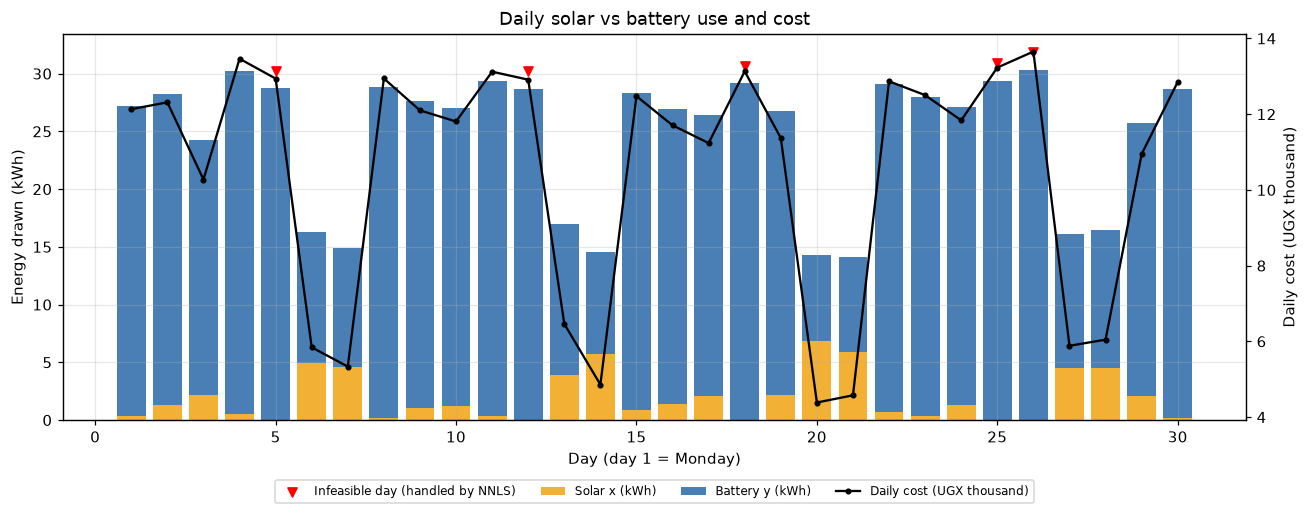

In [9]:
days = np.arange(1, len(D) + 1)
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.bar(days, X_nnls[:, 0], color="#f2b134", label="Solar x (kWh)")
ax.bar(days, X_nnls[:, 1], bottom=X_nnls[:, 0], color="#4a7fb5", label="Battery y (kWh)")
ax.scatter(days[mask], (X_nnls.sum(axis=1) + 1.5)[mask], marker="v", color="red", zorder=4, label="Infeasible day (handled by NNLS)")
ax.set(xlabel="Day (day 1 = Monday)", ylabel="Energy drawn (kWh)", title="Daily solar vs battery use and cost")
ax2 = ax.twinx()
ax2.plot(days, daily_cost / 1e3, "k.-", label="Daily cost (UGX thousand)")
ax2.set_ylabel("Daily cost (UGX thousand)"); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.14))
plt.tight_layout(); plt.show()

The chart supports one point: cost follows the **battery** bars almost exactly, because battery energy costs three times as much per kWh and supplies about ten times as many kWh as solar. The weekly rhythm (taller weekday bars, lower weekends) is the demand pattern passed straight through the linear system.

## Extension A. `HybridMicroGrid` with a diesel generator

`HybridMicroGrid(MicroGrid)` inherits the validation, determinant, condition number and solvers, and only changes the matrix. With diesel $z$ and my choice of third constraint (total energy dispatched equals a planned amount $D_3$):

$$3x+2y+z=D_1,\qquad 4x+y+z=D_2,\qquad x+y+z=D_3$$

In [10]:
hybrid = HybridMicroGrid()
print(hybrid)
d_mean = D.mean(axis=0)
D3 = 27.0                                   # planned total dispatch (kWh): my illustrative choice
s = hybrid.solve_day(d_mean[0], d_mean[1], D3)
print(f"Mean day D1={d_mean[0]:.1f}, D2={d_mean[1]:.1f}, D3={D3}: solar={s[0]:.2f}, battery={s[1]:.2f}, diesel={s[2]:.2f} kWh")
print("Check A @ s =", np.round(hybrid.A @ s, 6))

# A linearly dependent third equation: row3 = row1 + row2
dep = HybridMicroGrid([[3, 2, 1], [4, 1, 1], [7, 3, 2]])
print("\nDependent system:", dep.check_well_posed())
try:
    dep.solve_day(49, 30, 79)
except ValueError as e:
    print("solve_day ->", e)
print("Consistent RHS (D3 = D1 + D2 = 79): min-norm solution", np.round(dep.solve_least_squares([49, 30, 79]), 3),
      "| residual", np.round(dep.A @ dep.solve_least_squares([49, 30, 79]) - [49, 30, 79], 6))
print("Inconsistent RHS (D3 = 70):         best compromise  ", np.round(dep.solve_least_squares([49, 30, 70]), 3),
      "| residual", np.round(dep.A @ dep.solve_least_squares([49, 30, 70]) - [49, 30, 70], 3))
print("Null-space direction (free trade-off):", np.round(null_space(dep.A).ravel(), 3))

HybridMicroGrid(n=3, det=-3, cond=12.8)
Mean day D1=51.3, D2=30.5, D3=27.0: solar=1.16, battery=21.99, diesel=3.85 kWh
Check A @ s = [51.317667 30.492333 27.      ]

Dependent system: {'determinant': 0.0, 'condition_number': 1.921800810512402e+17, 'rank': 2, 'well_posed': False}
solve_day -> system is singular (linearly dependent equations): no unique solution
Consistent RHS (D3 = D1 + D2 = 79): min-norm solution [ 1.333 20.333  4.333] | residual [-0. -0. -0.]
Inconsistent RHS (D3 = 70):         best compromise   [ 0.778 19.778  4.111] | residual [-3. -3.  3.]
Null-space direction (free trade-off): [-0.192 -0.192  0.962]


**If the new equation is linearly dependent.** The determinant becomes zero (here about $10^{-16}$, i.e. rounding error), the rank drops to 2, and the condition number explodes to about $10^{17}$. Then one of two things happens. If the right-hand sides are **consistent** ($D_3 = D_1 + D_2$), there are *infinitely many* solutions: a whole line of dispatches, along the null-space direction printed above, that all meet the three equations exactly, so the planner must add a rule (such as minimum cost) to choose one. If they are **inconsistent**, there is *no* solution. `solve_day` refuses to guess and raises an error; `lstsq` returns the minimum-norm or best-compromise answer instead. The third equation added no new information, so the generator cannot be used to improve the dispatch.

## Extension B. Sensitivity to demand errors (Monte Carlo)

Perturb $D_1$ and $D_2$ independently by uniform $\pm5\%$ (1,000 draws, fixed seed) around the **mean demand day** and re-solve.

Base solution (mean day): solar = 1.93, battery = 22.76 kWh
Std of relative change under +/-5% demand noise: solar = 23.8%, battery = 5.7%
Largest |relative change| seen:                    solar = 56.0%, battery = 12.7%
Norm-wise amplification: mean = 1.93, max = 2.82, condition number = 5.83


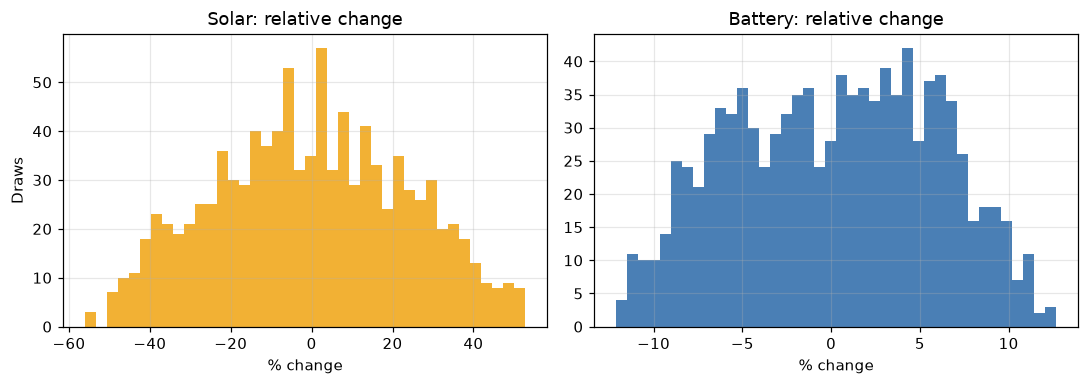

In [11]:
mc = monte_carlo_sensitivity(grid, d_mean, pct=0.05, n_draws=1000, seed=SEED)
rel = mc["rel_change_each"]
print(f"Base solution (mean day): solar = {mc['base'][0]:.2f}, battery = {mc['base'][1]:.2f} kWh")
print(f"Std of relative change under +/-5% demand noise: solar = {rel[:, 0].std():.1%}, battery = {rel[:, 1].std():.1%}")
print(f"Largest |relative change| seen:                    solar = {np.abs(rel[:, 0]).max():.1%}, battery = {np.abs(rel[:, 1]).max():.1%}")
print(f"Norm-wise amplification: mean = {mc['amplification'].mean():.2f}, max = {mc['amplification'].max():.2f}, "
      f"condition number = {mc['cond']:.2f}")
assert mc["amplification"].max() <= mc["cond"]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(rel[:, 0] * 100, bins=40, color="#f2b134"); ax[0].set(title="Solar: relative change", xlabel="% change", ylabel="Draws")
ax[1].hist(rel[:, 1] * 100, bins=40, color="#4a7fb5"); ax[1].set(title="Battery: relative change", xlabel="% change")
plt.tight_layout(); plt.show()

**Relating it to the condition number.** The norm-wise amplification (relative change in the solution divided by relative change in the demands) never exceeds $\kappa = 5.8$ and averages about 2, so the condition number is a valid but cautious upper bound. The histograms show the practical message: solar's *relative* uncertainty is several times larger than the battery's, even though the system is well-conditioned. That happens because solar is the small result of a cancellation, $x=(2D_2-D_1)/5$, so a 5% error in $D_1$ is large next to $x$ itself. The condition number bounds the error of the solution as a whole, not of each small component.

## Findings & Limitations

**The system is sound, but not every day is feasible.** The determinant is −5 and the condition number 5.8, so each day has one well-conditioned solution: x = (2D2 − D1)/5 and y = (4D1 − 3D2)/5. Uniqueness does not guarantee feasibility, though. Solar and battery are both non-negative only when D2/D1 lies between 0.5 and 1.33. Five of the 30 synthetic days (all weekdays) fall below that band, with exact solar between −0.43 and −0.03 kWh. Non-negative least squares handles them with a total leftover of 2.25 kWh against 5.03 for clipping. I set the weekday critical load low on purpose to create these days, so their number says nothing about a real clinic.

**Usage and cost.** The battery supplies about 22.7 kWh a day against 2.0 for solar, and accounts for 97% of the UGX 315,189 monthly cost. The battery is more volatile in absolute terms (standard deviation 7.9 against 2.1 kWh), solar in relative terms (CV 1.06 against 0.35). The vectorised solve was about 25 times faster than the loop on my machine.

**Sensitivity.** A ±5% error in demand changes solar by about 24% (standard deviation) but the battery by only 6%, because solar is the small remainder of a cancellation. The largest norm-wise amplification (2.8) stays below the condition number, which is a valid but cautious bound.

**Limitations.** The meaning of the coefficients 3, 2, 4 and 1 is not given, and I treat x and y as kWh drawn, as the scenario states. Demand is synthetic. The model has no battery state of charge, solar availability by hour, or capacity limits, and the prices are illustrative. The diesel constraint (total dispatch D3) is my own choice.